# Actividad 5 · Preparación de datos, entrenamiento y seguimiento de modelos

**Materia:** Gestión de Proyectos de Inteligencia Artificial  
**Dataset:** [Banking Dataset – Marketing Targets (Kaggle)](https://www.kaggle.com/datasets/prakharrathi25/banking-dataset-marketing-targets)  
**Problema:** predecir si un cliente contratará un depósito bancario a plazo (`y = yes/no`).  
**Algoritmos:** regresión logística y Random Forest.  
**Evaluación:** partición de prueba 20 %, GridSearchCV + validación cruzada estratificada (5 pliegues), clasificación y análisis estadístico.  
**Registro:** MLflow local; modelos, parámetros, métricas y artefactos.





## 1. Preparación de dependencias

In [1]:
# Instalar únicamente las dependencias no garantizadas en Colab.
# El resto (pandas, numpy, sklearn, matplotlib y scipy) se usa desde el entorno de Colab.
%pip -q install "kagglehub>=0.3,<1" "mlflow>=3.5,<4"

## 2. Configuración reproducible y directorios

In [2]:
import hashlib
import json
import os
import random
import shutil
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from mlflow.models import infer_signature
from scipy.stats import binomtest
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMILLA = 42
PROPORCION_PRUEBA = 0.20
PLIEGUES_CV = 5
KAGGLE_DATASET = "prakharrathi25/banking-dataset-marketing-targets"

random.seed(SEMILLA)
np.random.seed(SEMILLA)

RAIZ = Path("/content/Actividad5") if Path("/content").exists() else Path.cwd() / "Actividad5"
DATOS_ORIGINALES = RAIZ / "datos" / "datos_ini"
DATOS_LIMPIOS = RAIZ / "datos" / "datos_limp"
RESULTADOS = RAIZ / "resultados"
GRAFICAS = RESULTADOS / "graficas"
TABLAS = RESULTADOS / "tablas"
EVIDENCIAS = RAIZ / "evidencias"
MLRUNS = RAIZ / "mlruns"

for carpeta in (DATOS_ORIGINALES, DATOS_LIMPIOS, RESULTADOS, GRAFICAS, TABLAS, EVIDENCIAS, MLRUNS):
    carpeta.mkdir(parents=True, exist_ok=True)

versiones = {
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "mlflow": mlflow.__version__,
    "kagglehub": getattr(kagglehub, "__version__", "no_informada"),
}
(RAIZ / "versiones_entorno.json").write_text(
    json.dumps(versiones, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Directorio de trabajo:", RAIZ)
print("Versiones:")
display(pd.Series(versiones, name="version"))

Directorio de trabajo: /content/Actividad5
Versiones:


,version
python,3.13.16
pandas,2.2.3
numpy,2.1.3
scikit_learn,1.6.1
scipy,1.16.3
mlflow,3.17.2
kagglehub,0.4.3


## 3. Descarga automática desde Kaggle

In [3]:
# Download latest
path = kagglehub.dataset_download("prakharrathi25/banking-dataset-marketing-targets")

print("Path to dataset files:", path)
archivos_csv = sorted(Path(path).rglob("*.csv"))
print("Archivos CSV encontrados:", [archivo.name for archivo in archivos_csv])

# Se prioriza train.csv;
candidatos = [archivo for archivo in archivos_csv if archivo.name.lower() == "train.csv"]
if not candidatos:
    candidatos = [archivo for archivo in archivos_csv if archivo.name.lower() == "bank-full.csv"]
if not candidatos:
    raise FileNotFoundError(
        "No se encontró train.csv ni bank-full.csv. Archivos: "
        + str([archivo.name for archivo in archivos_csv])
    )
archivo_fuente = candidatos[0]
archivo_original = DATOS_ORIGINALES / archivo_fuente.name
shutil.copy2(archivo_fuente, archivo_original)

# El distribuidor puede publicar CSV separados por punto y coma o por coma.
datos_originales = pd.read_csv(archivo_original, sep=";", encoding="utf-8-sig")
if datos_originales.shape[1] == 1:
    datos_originales = pd.read_csv(archivo_original, sep=",", encoding="utf-8-sig")
if datos_originales.shape[1] < 5:
    raise ValueError("El CSV no pudo interpretarse correctamente: verifica el separador.")

print("Archivo utilizado:", archivo_original.name)
print("Dimensiones originales:", datos_originales.shape)
display(datos_originales.head(5))

100%|██████████| 576k/576k [00:00<00:00, 660kB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/prakharrathi25/banking-dataset-marketing-targets/versions/2
Archivos CSV encontrados: ['test.csv', 'train.csv']
Archivo utilizado: train.csv
Dimensiones originales: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 4. Limpieza, normalización y control de calidad

**Reglas documentadas:** nombres de columnas uniformes, eliminación de índices de exportación, normalización de etiquetas categóricas, interpretación de `unknown` como ausente, eliminación de etiquetas inválidas, eliminación de filas exactamente duplicadas y exclusión de `duration` por fuga de información.

Se **conservan valores extremos** de montos y edades cuando no puede demostrarse que sean errores. La imputación y el escalado se ajustan **dentro de cada partición** del pipeline (evita fuga de datos por preprocesamiento).

In [4]:
def calcular_sha256(archivo: Path) -> str:
    """Obtener huella criptográfica para identificar versiones del dataset."""
    resumen = hashlib.sha256()
    with archivo.open("rb") as entrada:
        for bloque in iter(lambda: entrada.read(1024 * 1024), b""):
            resumen.update(bloque)
    return resumen.hexdigest()


def limpiar_dataset(datos: pd.DataFrame):
    """Aplicar reglas de calidad sin aprender estadísticas del conjunto de prueba."""
    limpio = datos.copy()
    limpio.columns = [str(col).strip().lower() for col in limpio.columns]
    columnas_indice = [col for col in limpio if col.startswith("unnamed:")]
    limpio = limpio.drop(columns=columnas_indice)

    if "y" not in limpio.columns:
        raise KeyError(f"No se encontró la etiqueta 'y'. Columnas: {list(limpio.columns)}")

    categoricas = limpio.select_dtypes(include=["object", "string", "category"]).columns
    desconocidos_antes = {}
    for col in categoricas:
        serie = limpio[col].astype(str).str.strip().str.lower()
        desconocidos_antes[col] = int(serie.eq("unknown").sum())
        if col == "y":
            limpio[col] = serie
        else:
            limpio[col] = serie.replace(
                {"unknown": np.nan, "": np.nan, "nan": np.nan, "none": np.nan}
            )

    # Aceptamos exclusivamente las dos etiquetas declaradas por el dataset.
    etiquetas_validas = limpio["y"].isin(["yes", "no"])
    invalidas = int((~etiquetas_validas).sum())
    limpio = limpio.loc[etiquetas_validas].copy()
    limpio["y"] = limpio["y"].map({"no": 0, "yes": 1}).astype("int8")

    duplicados = int(limpio.duplicated().sum())
    limpio = limpio.drop_duplicates().reset_index(drop=True)
    eliminadas_fuga = [col for col in ["duration"] if col in limpio.columns]
    limpio = limpio.drop(columns=eliminadas_fuga)

    if limpio["y"].nunique() != 2:
        raise ValueError("Se requieren ambas clases de la variable objetivo.")

    informe = {
        "filas_originales": int(len(datos)),
        "filas_limpias": int(len(limpio)),
        "duplicados_exactos_eliminados": duplicados,
        "etiquetas_invalidas_eliminadas": invalidas,
        "columnas_indice_eliminadas": columnas_indice,
        "columnas_excluidas_por_fuga": eliminadas_fuga,
        "unknown_original_por_columna": desconocidos_antes,
        "ausentes_por_columna_limpia": {k: int(v) for k, v in limpio.isna().sum().items()},
        "objetivo": "y=1: contrató depósito; y=0: no contrató",
        "regla_pdays": "Se conserva -1 como no contactado anteriormente.",
        "regla_outliers": "Se analizan, pero no se eliminan sin evidencia de error.",
    }
    return limpio, informe


datos_limpios, informe_limpieza = limpiar_dataset(datos_originales)

archivo_limpio_estable = DATOS_LIMPIOS / "bank_marketing_limpio.csv"
datos_limpios.to_csv(archivo_limpio_estable, index=False)
hash_original = calcular_sha256(archivo_original)
hash_limpio = calcular_sha256(archivo_limpio_estable)
archivo_limpio_version = DATOS_LIMPIOS / f"bank_marketing_limpio_{hash_limpio[:12]}.csv"
shutil.copy2(archivo_limpio_estable, archivo_limpio_version)

manifiesto = {
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_kaggle": KAGGLE_DATASET,
    "url_kaggle": f"https://www.kaggle.com/datasets/{KAGGLE_DATASET}",
    "archivo_original": str(archivo_original.relative_to(RAIZ)),
    "sha256_original": hash_original,
    "archivo_limpio_versionado": str(archivo_limpio_version.relative_to(RAIZ)),
    "sha256_limpio": hash_limpio,
    "semilla": SEMILLA,
    "test_size": PROPORCION_PRUEBA,
    "cv_folds": PLIEGUES_CV,
    "reporte_limpieza": informe_limpieza,
}
archivo_manifiesto = RAIZ / "manifest_dataset.json"
archivo_manifiesto.write_text(
    json.dumps(manifiesto, indent=2, ensure_ascii=False), encoding="utf-8"
)

print("Control de calidad")
print(json.dumps(informe_limpieza, indent=2, ensure_ascii=False))
print("SHA-256 original:", hash_original)
print("SHA-256 limpio:", hash_limpio)
display(datos_limpios.head())

Control de calidad
{
  "filas_originales": 45211,
  "filas_limpias": 45211,
  "duplicados_exactos_eliminados": 0,
  "etiquetas_invalidas_eliminadas": 0,
  "columnas_indice_eliminadas": [],
  "columnas_excluidas_por_fuga": [
    "duration"
  ],
  "unknown_original_por_columna": {
    "job": 288,
    "marital": 0,
    "education": 1857,
    "default": 0,
    "housing": 0,
    "loan": 0,
    "contact": 13020,
    "month": 0,
    "poutcome": 36959,
    "y": 0
  },
  "ausentes_por_columna_limpia": {
    "age": 0,
    "job": 288,
    "marital": 0,
    "education": 1857,
    "default": 0,
    "balance": 0,
    "housing": 0,
    "loan": 0,
    "contact": 13020,
    "day": 0,
    "month": 0,
    "campaign": 0,
    "pdays": 0,
    "previous": 0,
    "poutcome": 36959,
    "y": 0
  },
  "objetivo": "y=1: contrató depósito; y=0: no contrató",
  "regla_pdays": "Se conserva -1 como no contactado anteriormente.",
  "regla_outliers": "Se analizan, pero no se eliminan sin evidencia de error."
}
SHA-256

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,1,-1,0,NaN,0
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,1,-1,0,NaN,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,1,-1,0,NaN,0
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,1,-1,0,NaN,0
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,1,-1,0,NaN,0


### Diccionario de datos y análisis exploratorio

La fuente contiene variables demográficas, situación financiera y antecedentes de campañas bancarias. La variable `duration` se conserva únicamente en el archivo **original** para garantizar auditoría de la exclusión; no se emplea como predictor.

In [5]:
diccionario = {
    "age": "Edad del cliente (años).",
    "job": "Tipo de empleo.",
    "marital": "Estado civil.",
    "education": "Nivel educativo.",
    "default": "Indicación de incumplimiento de crédito.",
    "balance": "Saldo anual promedio, en unidades monetarias del dataset.",
    "housing": "Indicación de préstamo hipotecario.",
    "loan": "Indicación de préstamo personal.",
    "contact": "Tipo de canal de contacto.",
    "day": "Día del mes del último contacto.",
    "month": "Mes del último contacto.",
    "duration": "Duración del último contacto (excluida: fuga de información).",
    "campaign": "Número de contactos en la campaña actual.",
    "pdays": "Días desde contacto anterior; -1 indica nunca contactado.",
    "previous": "Número de contactos antes de la campaña actual.",
    "poutcome": "Resultado de la campaña anterior.",
    "y": "Variable objetivo: 1 sí contrató, 0 no contrató.",
}
columnas_diccionario = [col for col in datos_originales.columns if col.lower().strip() in diccionario]
tabla_diccionario = pd.DataFrame({
    "variable": columnas_diccionario,
    "descripcion": [diccionario[col.lower().strip()] for col in columnas_diccionario],
    "tipo_original": [str(datos_originales[col].dtype) for col in columnas_diccionario],
})
tabla_diccionario.to_csv(TABLAS / "diccionario_datos.csv", index=False)

tabla_calidad = pd.DataFrame({
    "variable": datos_limpios.columns,
    "tipo": [str(tipo) for tipo in datos_limpios.dtypes],
    "nulos": datos_limpios.isna().sum().values,
    "porcentaje_nulos": (100 * datos_limpios.isna().mean()).round(2).values,
    "valores_unicos": datos_limpios.nunique(dropna=True).values,
})
tabla_calidad.to_csv(TABLAS / "calidad_datos.csv", index=False)
tabla_balance = (
    datos_limpios["y"].value_counts().sort_index()
    .rename_axis("clase").reset_index(name="registros")
)
tabla_balance["porcentaje"] = (
    100 * tabla_balance["registros"] / len(datos_limpios)
).round(2)
tabla_balance.to_csv(TABLAS / "distribucion_objetivo.csv", index=False)

print("Diccionario de datos:")
display(tabla_diccionario)
print("Distribución de la clase objetivo:")
display(tabla_balance)
print("Calidad de los datos:")
display(tabla_calidad)

Diccionario de datos:


,variable,descripcion,tipo_original
0,age,Edad del cliente (años).,int64
1,job,Tipo de empleo.,object
2,marital,Estado civil.,object
3,education,Nivel educativo.,object
4,default,Indicación de incumplimiento de crédito.,object
5,balance,"Saldo anual promedio, en unidades monetarias d...",int64
6,housing,Indicación de préstamo hipotecario.,object
7,loan,Indicación de préstamo personal.,object
8,contact,Tipo de canal de contacto.,object
9,day,Día del mes del último contacto.,int64


Distribución de la clase objetivo:


,clase,registros,porcentaje
0,0,39922,88.3
1,1,5289,11.7


Calidad de los datos:


,variable,tipo,nulos,porcentaje_nulos,valores_unicos
0,age,int64,0,0.00,77
1,job,object,288,0.64,11
2,marital,object,0,0.00,3
3,education,object,1857,4.11,3
4,default,object,0,0.00,2
5,balance,int64,0,0.00,7168
6,housing,object,0,0.00,2
7,loan,object,0,0.00,2
8,contact,object,13020,28.80,2
9,day,int64,0,0.00,31


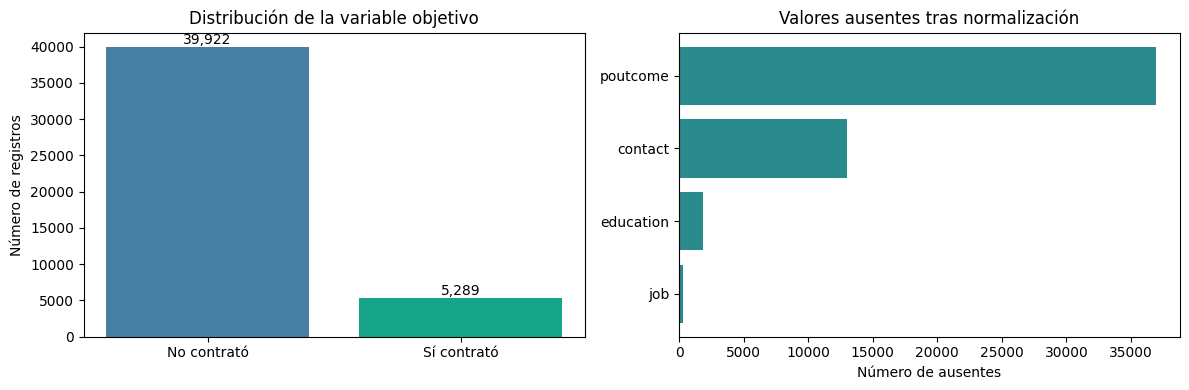

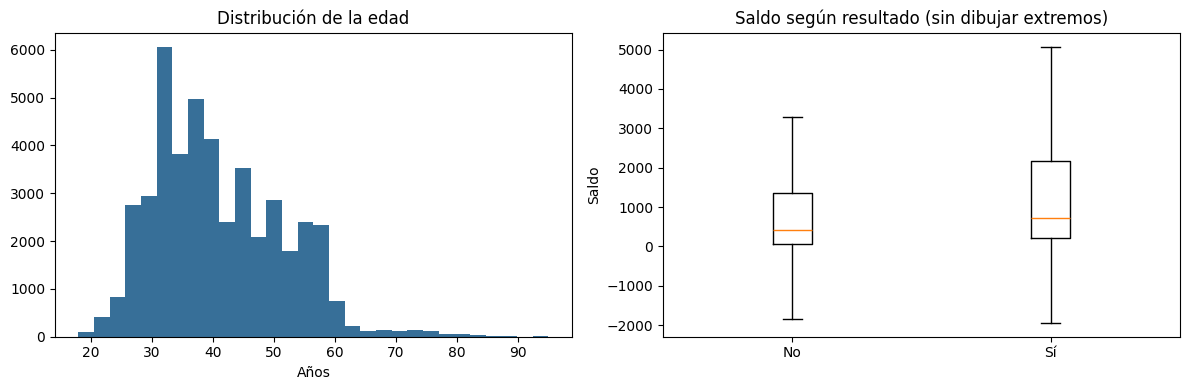

,variable,limite_inferior_iqr,limite_superior_iqr,posibles_atipicos,porcentaje,decision
0,age,10.5,70.5,487,1.08,Conservar: falta evidencia de que sean errores
1,balance,-1962.0,3462.0,4729,10.46,Conservar: falta evidencia de que sean errores
2,campaign,-2.0,6.0,3064,6.78,Conservar: falta evidencia de que sean errores


In [6]:
# Gráficas exploratorias. Todos los porcentajes proceden de los datos realmente descargados.
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
valores_clase = datos_limpios["y"].value_counts().reindex([0, 1], fill_value=0)
ejes[0].bar(["No contrató", "Sí contrató"], valores_clase.values, color=["#477fa3", "#17a589"])
ejes[0].set_title("Distribución de la variable objetivo")
ejes[0].set_ylabel("Número de registros")
for i, valor in enumerate(valores_clase.values):
    ejes[0].text(i, valor, f"{valor:,}", ha="center", va="bottom")

nulos = datos_limpios.isna().sum().sort_values(ascending=False)
nulos = nulos.loc[nulos > 0]
if len(nulos):
    ejes[1].barh(nulos.index[::-1], nulos.values[::-1], color="#2a8a8d")
    ejes[1].set_xlabel("Número de ausentes")
else:
    ejes[1].text(0.5, 0.5, "No se detectaron ausentes", ha="center", va="center")
    ejes[1].set_axis_off()
ejes[1].set_title("Valores ausentes tras normalización")
fig.tight_layout()
fig.savefig(GRAFICAS / "01_calidad_y_clases.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
if "age" in datos_limpios:
    ejes[0].hist(datos_limpios["age"].dropna(), bins=30, color="#376f98")
    ejes[0].set_title("Distribución de la edad")
    ejes[0].set_xlabel("Años")
if "balance" in datos_limpios:
    grupos = [datos_limpios.loc[datos_limpios["y"].eq(k), "balance"].dropna() for k in [0, 1]]
    ejes[1].boxplot(grupos, tick_labels=["No", "Sí"], showfliers=False)
    ejes[1].set_title("Saldo según resultado (sin dibujar extremos)")
    ejes[1].set_ylabel("Saldo")
fig.tight_layout()
fig.savefig(GRAFICAS / "02_edad_y_saldo.png", dpi=180, bbox_inches="tight")
plt.show()

# Detectar observaciones extremas como posibles anomalías; no eliminarlas sin justificación.
filas_atipicos = []
for variable in ["age", "balance", "campaign"]:
    if variable not in datos_limpios:
        continue
    serie = pd.to_numeric(datos_limpios[variable], errors="coerce").dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    rango_iqr = q3 - q1
    limite_inf, limite_sup = q1 - 1.5 * rango_iqr, q3 + 1.5 * rango_iqr
    cantidad = int(((serie < limite_inf) | (serie > limite_sup)).sum())
    filas_atipicos.append({
        "variable": variable, "limite_inferior_iqr": limite_inf,
        "limite_superior_iqr": limite_sup, "posibles_atipicos": cantidad,
        "porcentaje": round(100 * cantidad / len(serie), 2),
        "decision": "Conservar: falta evidencia de que sean errores",
    })
tabla_atipicos = pd.DataFrame(filas_atipicos)
tabla_atipicos.to_csv(TABLAS / "posibles_atipicos.csv", index=False)
display(tabla_atipicos)

## 5. Separación estratificada y preprocesamiento sin fuga

Se reserva el **20 %** para prueba final, sin utilizarlo durante la búsqueda de hiperparámetros. `GridSearchCV` usa **cinco pliegues estratificados** sobre el 80 % restante.

- **Regresión logística:** imputación, One-Hot Encoding y `StandardScaler` para variables numéricas.
- **Random Forest:** imputación y One-Hot Encoding, sin escalado innecesario para árboles.
- `unknown` se imputa dentro del pipeline de cada pliegue; `pdays=-1` mantiene su interpretación de negocio.
- **Métrica principal para optimizar y elegir modelo:** área bajo la curva precisión-recall (`average_precision`, PR-AUC), apropiada para el desbalance de clases. Se reportan también accuracy, precision, recall, F1, balanced accuracy y ROC-AUC.

In [7]:
X = datos_limpios.drop(columns="y")
y = datos_limpios["y"]
assert "duration" not in X.columns, "Fuga de información: duration sigue en los predictores."

numericas = X.select_dtypes(include=["number"]).columns.tolist()
categoricas = X.select_dtypes(exclude=["number"]).columns.tolist()
assert numericas and categoricas, "Se requieren variables numéricas y categóricas."

X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    X, y, test_size=PROPORCION_PRUEBA, random_state=SEMILLA, stratify=y
)
assert not set(X_entrena.index).intersection(set(X_prueba.index))

preproc_logistica = ColumnTransformer(transformers=[
    ("numericas", Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
    ]), numericas),
    ("categoricas", Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(handle_unknown="ignore")),
    ]), categoricas),
])
preproc_bosque = ColumnTransformer(transformers=[
    ("numericas", SimpleImputer(strategy="median"), numericas),
    ("categoricas", Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(handle_unknown="ignore")),
    ]), categoricas),
])

print("Variables numéricas:", numericas)
print("Variables categóricas:", categoricas)
print("Entrenamiento:", X_entrena.shape, " | Prueba:", X_prueba.shape)
print("Positivos entrenamiento:", round(y_entrena.mean() * 100, 2), "%")
print("Positivos prueba:", round(y_prueba.mean() * 100, 2), "%")

Variables numéricas: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Entrenamiento: (36168, 15)  | Prueba: (9043, 15)
Positivos entrenamiento: 11.7 %
Positivos prueba: 11.7 %


## 6. Modelos, hiperparámetros y MLflow

**Justificación del ajuste:** `C` controla la regularización de la regresión logística; `class_weight` permite explorar el tratamiento del desbalance. En el bosque, `max_depth` y `min_samples_leaf` regulan la complejidad, y `class_weight` permite ponderar clases. Se fijan **150 árboles** para limitar el costo de cómputo en Colab. Todos los candidatos usan los **mismos cinco pliegues**.

El proceso puede tardar varios minutos. No cierres el entorno mientras se entrena.

In [8]:
import os
# Permitir el uso del backend de almacenamiento en disco local (FileStore) en MLflow 3+
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

validacion_cruzada = StratifiedKFold(
    n_splits=PLIEGUES_CV, shuffle=True, random_state=SEMILLA
)
metricas_cv = {
    "pr_auc": "average_precision", "roc_auc": "roc_auc",
    "f1": "f1", "accuracy": "accuracy", "recall": "recall",
}

experimentos = {
    "Regresion_logistica": {
        "pipeline": Pipeline(steps=[
            ("preprocesamiento", preproc_logistica),
            ("modelo", LogisticRegression(max_iter=2000, solver="lbfgs", random_state=SEMILLA)),
        ]),
        "grid": {
            "modelo__C": [0.1, 1.0, 10.0],
            "modelo__class_weight": [None, "balanced"],
        },
    },
    "Random_Forest": {
        "pipeline": Pipeline(steps=[
            ("preprocesamiento", preproc_bosque),
            ("modelo", RandomForestClassifier(n_estimators=150, n_jobs=1, random_state=SEMILLA)),
        ]),
        "grid": {
            "modelo__max_depth": [12, None],
            "modelo__min_samples_leaf": [1, 5],
            "modelo__class_weight": [None, "balanced_subsample"],
        },
    },
}

mlflow.set_tracking_uri(MLRUNS.resolve().as_uri())
mlflow.set_experiment("Actividad5_BankMarketing_Kaggle")
print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Configuraciones a evaluar:", {
    nombre: int(np.prod([len(v) for v in cfg["grid"].values()]))
    for nombre, cfg in experimentos.items()
})

2026/10/26 06:07:07 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5_BankMarketing_Kaggle' does not exist. Creating a new experiment.


MLflow tracking URI: file:///content/Actividad5/mlruns
Configuraciones a evaluar: {'Regresion_logistica': 6, 'Random_Forest': 8}


In [9]:
def obtener_metricas(y_real, predicciones, probabilidades):
    """Métricas estandarizadas para la clase positiva: contratación (1)."""
    return {
        "accuracy": float(accuracy_score(y_real, predicciones)),
        "balanced_accuracy": float(balanced_accuracy_score(y_real, predicciones)),
        "precision": float(precision_score(y_real, predicciones, zero_division=0)),
        "recall": float(recall_score(y_real, predicciones, zero_division=0)),
        "f1": float(f1_score(y_real, predicciones, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_real, probabilidades)),
        "pr_auc": float(average_precision_score(y_real, probabilidades)),
    }


def guardar_matriz_confusion(y_real, predicciones, nombre_archivo):
    matriz = confusion_matrix(y_real, predicciones, labels=[0, 1])
    figura, eje = plt.subplots(figsize=(5.5, 4.5))
    ConfusionMatrixDisplay(
        matriz, display_labels=["No contrató", "Sí contrató"]
    ).plot(ax=eje, cmap="Blues", values_format="d", colorbar=False)
    eje.set_title(nombre_archivo.replace("_", " "))
    figura.tight_layout()
    ruta = GRAFICAS / f"matriz_{nombre_archivo}.png"
    figura.savefig(ruta, dpi=180, bbox_inches="tight")
    plt.show()
    return ruta

resultados_modelos = []
modelos_ajustados = {}
predicciones_modelos = {}
probabilidades_modelos = {}
ids_corridas = {}
modelos_uris = {}

## 7. Entrenamiento, GridSearchCV y registro de experimentos


Entrenando: Regresion_logistica
Fitting 5 folds for each of 6 candidates, totalling 30 fits


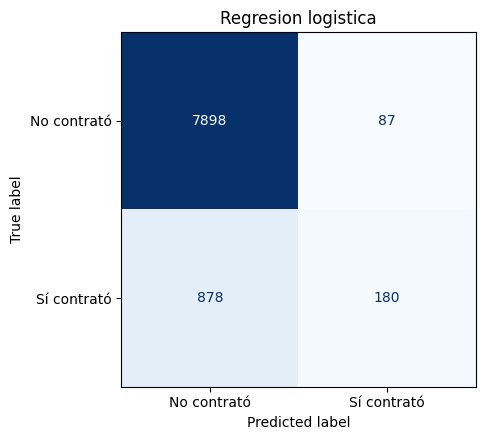

/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/26 06:07:41 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during de

Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__class_weight': None}
PR-AUC CV: 0.3866
F1 prueba: 0.2717
ROC-AUC prueba: 0.7519
Run de MLflow: 40101650ef7b4360bdc4bbe2f375660f

Entrenando: Random_Forest
Fitting 5 folds for each of 8 candidates, totalling 40 fits


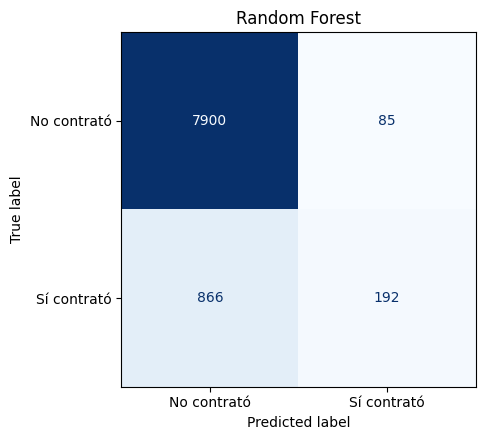

/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/26 06:11:08 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during de

Mejores hiperparámetros: {'modelo__class_weight': None, 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}
PR-AUC CV: 0.4316
F1 prueba: 0.2876
ROC-AUC prueba: 0.7908
Run de MLflow: 74a8f991849841d7b84a814058e76de4

Entrenamiento terminado. Se registraron 2 corridas en MLflow.


In [10]:
for nombre, configuracion in experimentos.items():
    print("\n" + "=" * 72)
    print("Entrenando:", nombre)
    tiempo_inicio = time.perf_counter()

    busqueda = GridSearchCV(
        estimator=configuracion["pipeline"],
        param_grid=configuracion["grid"],
        scoring=metricas_cv,
        refit="pr_auc",  # No se elige el modelo mirando el conjunto de prueba.
        cv=validacion_cruzada,
        n_jobs=2,
        verbose=1,
        return_train_score=True,
        error_score="raise",
    )
    busqueda.fit(X_entrena, y_entrena)
    duracion_entrenamiento = time.perf_counter() - tiempo_inicio

    mejor_modelo = busqueda.best_estimator_
    prediccion = mejor_modelo.predict(X_prueba)
    probabilidad = mejor_modelo.predict_proba(X_prueba)[:, 1]
    pred_entrenamiento = mejor_modelo.predict(X_entrena)
    prob_entrenamiento = mejor_modelo.predict_proba(X_entrena)[:, 1]
    metricas_prueba = obtener_metricas(y_prueba, prediccion, probabilidad)
    metricas_entrenamiento = obtener_metricas(
        y_entrena, pred_entrenamiento, prob_entrenamiento
    )
    metricas_mejor_cv = {
        metrica: float(busqueda.cv_results_[f"mean_test_{metrica}"][busqueda.best_index_])
        for metrica in metricas_cv
    }

    tabla_cv = pd.DataFrame(busqueda.cv_results_).sort_values("rank_test_pr_auc")
    ruta_cv = TABLAS / f"grid_search_{nombre}.csv"
    tabla_cv.to_csv(ruta_cv, index=False)

    informe_clasificacion = pd.DataFrame(
        classification_report(
            y_prueba, prediccion, target_names=["No", "Sí"],
            output_dict=True, zero_division=0
        )
    ).T
    ruta_reporte = TABLAS / f"classification_report_{nombre}.csv"
    informe_clasificacion.to_csv(ruta_reporte)
    ruta_matriz = guardar_matriz_confusion(y_prueba, prediccion, nombre)

    with mlflow.start_run(run_name=nombre) as corrida:
        id_corrida = corrida.info.run_id
        mlflow.set_tags({
            "fuente": "Kaggle",
            "dataset": KAGGLE_DATASET,
            "sha256_datos_originales": hash_original,
            "sha256_datos_limpios": hash_limpio,
            "semilla": str(SEMILLA),
            "modelo": nombre,
            "fuga_duration": "excluida",
        })
        mlflow.log_params({
            "test_size": PROPORCION_PRUEBA,
            "cv_folds": PLIEGUES_CV,
            "cv_refit": "pr_auc",
            "filas_entrenamiento": len(X_entrena),
            "filas_prueba": len(X_prueba),
            "num_configuraciones": len(busqueda.cv_results_["params"]),
        })
        mlflow.log_params({f"mejor_{k}": str(v) for k, v in busqueda.best_params_.items()})
        mlflow.log_metric("entrenamiento_segundos", duracion_entrenamiento)
        for metrica, valor in metricas_mejor_cv.items():
            mlflow.log_metric(f"cv_{metrica}", valor)
        for metrica, valor in metricas_prueba.items():
            mlflow.log_metric(f"test_{metrica}", valor)
        for metrica in ("f1", "pr_auc", "roc_auc"):
            mlflow.log_metric(f"train_{metrica}", metricas_entrenamiento[metrica])
        mlflow.log_artifact(str(archivo_manifiesto), artifact_path="datos")
        mlflow.log_artifact(str(ruta_cv), artifact_path="validacion_cruzada")
        mlflow.log_artifact(str(ruta_reporte), artifact_path="evaluacion")
        mlflow.log_artifact(str(ruta_matriz), artifact_path="graficas")

        # En MLflow 3 se utiliza 'name' y se guarda la firma del modelo.
        ejemplo = X_entrena.dropna().head(5)
        if ejemplo.empty:
            ejemplo = X_entrena.head(5)
        firma = infer_signature(ejemplo, mejor_modelo.predict(ejemplo))
        info_modelo = mlflow.sklearn.log_model(
            sk_model=mejor_modelo,
            name=f"modelo_{nombre.lower()}",
            signature=firma,
            input_example=ejemplo,
            serialization_format="cloudpickle"  # Serialización universal segura y estable para pipelines de sklearn complejos en Colab
        )
        modelos_uris[nombre] = info_modelo.model_uri
        ids_corridas[nombre] = id_corrida

    modelos_ajustados[nombre] = mejor_modelo
    predicciones_modelos[nombre] = np.asarray(prediccion)
    probabilidades_modelos[nombre] = np.asarray(probabilidad)
    resultados_modelos.append({
        "modelo": nombre,
        "train_f1": metricas_entrenamiento["f1"],
        "cv_pr_auc": metricas_mejor_cv["pr_auc"],
        "cv_roc_auc": metricas_mejor_cv["roc_auc"],
        "cv_f1": metricas_mejor_cv["f1"],
        **{f"test_{k}": v for k, v in metricas_prueba.items()},
        "segundos_entrenamiento": duracion_entrenamiento,
        "run_id_mlflow": ids_corridas[nombre],
        "model_uri_mlflow": modelos_uris[nombre],
    })
    print("Mejores hiperparámetros:", busqueda.best_params_)
    print("PR-AUC CV:", round(metricas_mejor_cv["pr_auc"], 4))
    print("F1 prueba:", round(metricas_prueba["f1"], 4))
    print("ROC-AUC prueba:", round(metricas_prueba["roc_auc"], 4))
    print("Run de MLflow:", id_corrida)

print("\nEntrenamiento terminado. Se registraron", len(ids_corridas), "corridas en MLflow.")

## 8. Comparación final y gráficas de evaluación

Modelo seleccionado por PR-AUC de validación cruzada: Random_Forest
La elección es por CV, no por la métrica del conjunto de prueba.


,modelo,train_f1,cv_pr_auc,cv_roc_auc,cv_f1,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc,segundos_entrenamiento,run_id_mlflow,model_uri_mlflow
0,Random_Forest,0.3769,0.4316,0.7757,0.2896,0.8948,0.5854,0.6931,0.1815,0.2876,0.7908,0.4433,197.5355,74a8f991849841d7b84a814058e76de4,models:/m-4464823997f242e0bc7cd68dcc94c2a9
1,Regresion_logistica,0.2663,0.3866,0.7447,0.2616,0.8933,0.5796,0.6742,0.1701,0.2717,0.7519,0.3960,33.4190,40101650ef7b4360bdc4bbe2f375660f,models:/m-49413c3fce8c4ad7afe4d01bb1fbb429


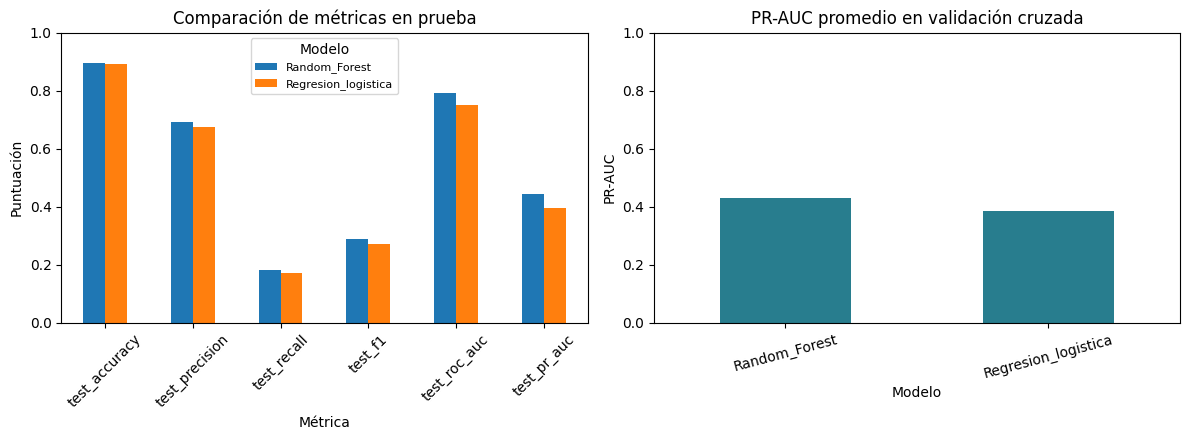

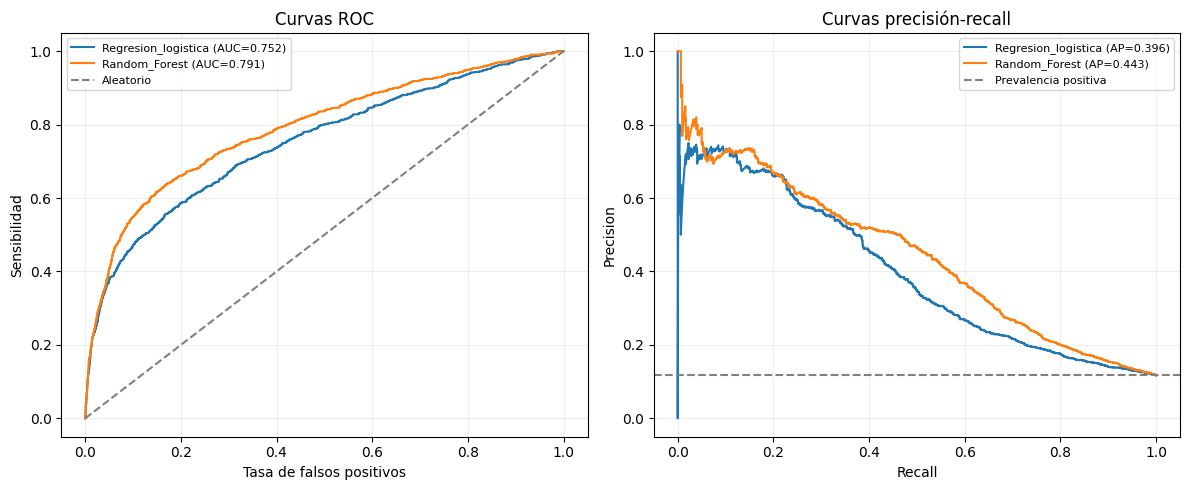

In [11]:
tabla_resultados = (
    pd.DataFrame(resultados_modelos)
    .sort_values("cv_pr_auc", ascending=False)
    .reset_index(drop=True)
)
tabla_resultados.to_csv(TABLAS / "comparacion_modelos.csv", index=False)

ganador_cv = tabla_resultados.loc[0, "modelo"]
print("Modelo seleccionado por PR-AUC de validación cruzada:", ganador_cv)
print("La elección es por CV, no por la métrica del conjunto de prueba.")
display(tabla_resultados.round(4))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
indicadores = ["test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc", "test_pr_auc"]
tabla_resultados.set_index("modelo")[indicadores].T.plot(kind="bar", ax=ejes[0])
ejes[0].set_title("Comparación de métricas en prueba")
ejes[0].set_xlabel("Métrica")
ejes[0].set_ylabel("Puntuación")
ejes[0].set_ylim(0, 1)
ejes[0].tick_params(axis="x", labelrotation=45)
ejes[0].legend(title="Modelo", fontsize=8)

tabla_resultados.set_index("modelo")["cv_pr_auc"].plot(
    kind="bar", ax=ejes[1], color="#287d8e"
)
ejes[1].set_title("PR-AUC promedio en validación cruzada")
ejes[1].set_ylim(0, 1)
ejes[1].set_xlabel("Modelo")
ejes[1].set_ylabel("PR-AUC")
ejes[1].tick_params(axis="x", labelrotation=15)
fig.tight_layout()
fig.savefig(GRAFICAS / "03_comparacion_modelos.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for nombre in modelos_ajustados:
    fpr, tpr, _ = roc_curve(y_prueba, probabilidades_modelos[nombre])
    precision, recall, _ = precision_recall_curve(y_prueba, probabilidades_modelos[nombre])
    auc_roc = roc_auc_score(y_prueba, probabilidades_modelos[nombre])
    auc_pr = average_precision_score(y_prueba, probabilidades_modelos[nombre])
    ejes[0].plot(fpr, tpr, label=f"{nombre} (AUC={auc_roc:.3f})")
    ejes[1].plot(recall, precision, label=f"{nombre} (AP={auc_pr:.3f})")

ejes[0].plot([0, 1], [0, 1], "--", color="gray", label="Aleatorio")
ejes[1].axhline(y_prueba.mean(), linestyle="--", color="gray", label="Prevalencia positiva")
ejes[0].set(title="Curvas ROC", xlabel="Tasa de falsos positivos", ylabel="Sensibilidad")
ejes[1].set(title="Curvas precisión-recall", xlabel="Recall", ylabel="Precision")
for eje in ejes:
    eje.legend(fontsize=8)
    eje.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(GRAFICAS / "04_curvas_roc_pr.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Comparación estadística básica

Se usa una comparación **pareada** sobre las mismas observaciones de prueba. McNemar exacto contrasta diferencias en aciertos/errores de clasificación; un *bootstrap* pareado estima el intervalo del 95 % para la diferencia de F1. No implica causalidad ni sustituye validaciones temporales o en producción. Ambos resultados se interpretan aparte del criterio de selección por CV.

In [12]:
modelo_a, modelo_b = list(modelos_ajustados.keys())
verdad = y_prueba.to_numpy()
pred_a = predicciones_modelos[modelo_a]
pred_b = predicciones_modelos[modelo_b]
correcto_a = pred_a == verdad
correcto_b = pred_b == verdad

solo_a_acierta = int(np.sum(correcto_a & ~correcto_b))
solo_b_acierta = int(np.sum(~correcto_a & correcto_b))
discordantes = solo_a_acierta + solo_b_acierta
p_mcnemar = (
    float(binomtest(min(solo_a_acierta, solo_b_acierta), discordantes, 0.5).pvalue)
    if discordantes > 0 else 1.0
)

aleatorio = np.random.default_rng(SEMILLA)
DIFERENCIAS_BOOTSTRAP = 1000
diferencias_f1 = np.empty(DIFERENCIAS_BOOTSTRAP)
for repeticion in range(DIFERENCIAS_BOOTSTRAP):
    indices = aleatorio.integers(0, len(verdad), len(verdad))
    diferencias_f1[repeticion] = (
        f1_score(verdad[indices], pred_a[indices], zero_division=0)
        - f1_score(verdad[indices], pred_b[indices], zero_division=0)
    )
limite_inferior, limite_superior = np.quantile(diferencias_f1, [0.025, 0.975])

tabla_estadistica = pd.DataFrame([{
    "modelo_a": modelo_a,
    "modelo_b": modelo_b,
    "solo_a_acierta": solo_a_acierta,
    "solo_b_acierta": solo_b_acierta,
    "mcnemar_p_exacto": p_mcnemar,
    "diferencia_f1_a_menos_b": float(f1_score(verdad, pred_a) - f1_score(verdad, pred_b)),
    "ic95_f1_diferencia_inferior": float(limite_inferior),
    "ic95_f1_diferencia_superior": float(limite_superior),
    "repeticiones_bootstrap": DIFERENCIAS_BOOTSTRAP,
}])
tabla_estadistica.to_csv(TABLAS / "comparacion_estadistica.csv", index=False)
display(tabla_estadistica.round(5))
print(
    "Interpretación McNemar:",
    "evidencia de diferencia en errores (p < 0.05)" if p_mcnemar < 0.05
    else "sin evidencia suficiente de diferencia en errores al 5 %",
)

,modelo_a,modelo_b,solo_a_acierta,solo_b_acierta,mcnemar_p_exacto,diferencia_f1_a_menos_b,ic95_f1_diferencia_inferior,ic95_f1_diferencia_superior,repeticiones_bootstrap
0,Regresion_logistica,Random_Forest,41,55,0.18429,-0.01594,-0.03287,0.00105,1000


Interpretación McNemar: sin evidencia suficiente de diferencia en errores al 5 %


## 10. Interpretación de variables y evidencia MLflow

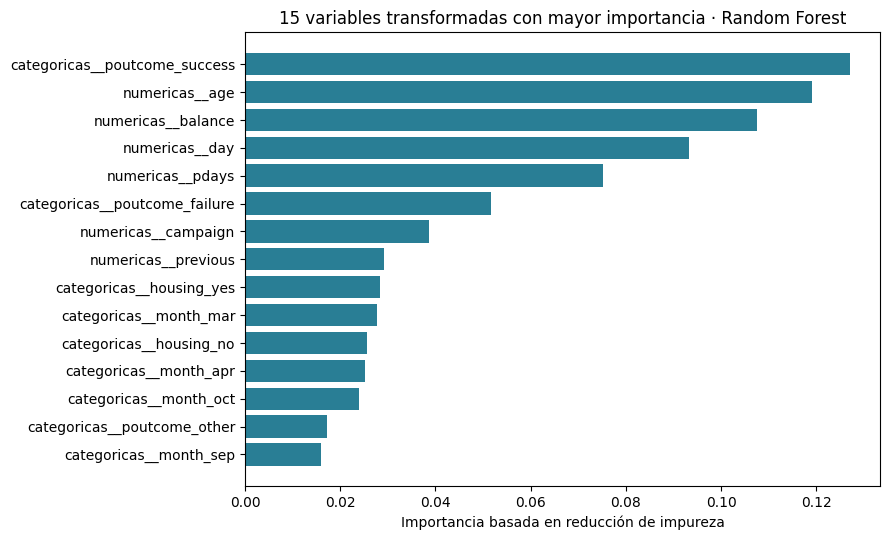

,variable_transformada,importancia
45,categoricas__poutcome_success,0.126987
0,numericas__age,0.118979
1,numericas__balance,0.107550
2,numericas__day,0.093138
4,numericas__pdays,0.075249
43,categoricas__poutcome_failure,0.051592
3,numericas__campaign,0.038577
5,numericas__previous,0.029091
26,categoricas__housing_yes,0.028338
38,categoricas__month_mar,0.027641


Resumen del experimento en MLflow:


,tags.mlflow.runName,metrics.cv_pr_auc,metrics.test_f1,metrics.test_roc_auc,metrics.test_precision,metrics.test_recall,metrics.entrenamiento_segundos,run_id
0,Random_Forest,0.431596,0.287640,0.790849,0.693141,0.181474,197.535457,74a8f991849841d7b84a814058e76de4
1,Regresion_logistica,0.386612,0.271698,0.751921,0.674157,0.170132,33.418960,40101650ef7b4360bdc4bbe2f375660f


Archivos de seguimiento: /content/Actividad5/mlruns
ID del mejor modelo: 74a8f991849841d7b84a814058e76de4
URI del modelo: models:/m-4464823997f242e0bc7cd68dcc94c2a9


In [13]:
# Importancia de variables transformadas en Random Forest.
# Advertencia: la importancia por impureza puede sesgarse hacia variables de muchas categorías.
bosque_final = modelos_ajustados["Random_Forest"]
transformador = bosque_final.named_steps["preprocesamiento"]
columnas_transformadas = transformador.get_feature_names_out()
importancias = bosque_final.named_steps["modelo"].feature_importances_
if len(columnas_transformadas) != len(importancias):
    raise ValueError("La lista de características no coincide con las importancias.")
tabla_importancia = (
    pd.DataFrame({"variable_transformada": columnas_transformadas, "importancia": importancias})
    .sort_values("importancia", ascending=False)
)
tabla_importancia.to_csv(TABLAS / "importancias_random_forest.csv", index=False)

fig, eje = plt.subplots(figsize=(9, 5.5))
principales = tabla_importancia.head(15).iloc[::-1]
eje.barh(principales["variable_transformada"], principales["importancia"], color="#297e95")
eje.set_title("15 variables transformadas con mayor importancia · Random Forest")
eje.set_xlabel("Importancia basada en reducción de impureza")
fig.tight_layout()
fig.savefig(GRAFICAS / "05_importancia_variables.png", dpi=180, bbox_inches="tight")
plt.show()

display(tabla_importancia.head(15))

# Incorporar el resumen y los gráficos consolidados al run del modelo ganador.
with mlflow.start_run(run_id=ids_corridas[ganador_cv]):
    mlflow.set_tag("modelo_seleccionado_por_cv", "true")
    mlflow.log_artifact(str(TABLAS / "comparacion_modelos.csv"), artifact_path="comparacion")
    mlflow.log_artifact(str(TABLAS / "comparacion_estadistica.csv"), artifact_path="comparacion")
    mlflow.log_artifact(str(TABLAS / "importancias_random_forest.csv"), artifact_path="interpretacion")
    for archivo_grafica in GRAFICAS.glob("*.png"):
        mlflow.log_artifact(str(archivo_grafica), artifact_path="graficas")

print("Resumen del experimento en MLflow:")
experiment_name = "Actividad5_BankMarketing_Kaggle"
experiment_info = mlflow.get_experiment_by_name(experiment_name)
registradas = mlflow.search_runs(experiment_ids=[experiment_info.experiment_id])
columnas_mlflow = [
    "tags.mlflow.runName", "metrics.cv_pr_auc", "metrics.test_f1",
    "metrics.test_roc_auc", "metrics.test_precision", "metrics.test_recall",
    "metrics.entrenamiento_segundos", "run_id",
]
columnas_mlflow = [col for col in columnas_mlflow if col in registradas.columns]
display(registradas[columnas_mlflow].head(10))
registradas.to_csv(TABLAS / "mlflow_corridas.csv", index=False)
print("Archivos de seguimiento:", MLRUNS)
print("ID del mejor modelo:", ids_corridas[ganador_cv])
print("URI del modelo:", modelos_uris[ganador_cv])